In [2]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [6]:
from google.colab import files

uploaded = files.upload()

Saving weatherAUS.csv to weatherAUS (1).csv


In [8]:
df = pd.read_csv("weatherAUS.csv")

X = df.drop("RainTomorrow", axis=1)
y = df["RainTomorrow"]

In [9]:
# Check missing values

print(df.isnull().sum())

Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64


In [10]:
# Remove rows containing missing values

df = df.dropna()

print("Dataset after removing missing values:")
print(df.head())

Dataset after removing missing values:
            Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
6049  2009-01-01    Cobar     17.9     35.2       0.0         12.0      12.3   
6050  2009-01-02    Cobar     18.4     28.9       0.0         14.8      13.0   
6052  2009-01-04    Cobar     19.4     37.6       0.0         10.8      10.6   
6053  2009-01-05    Cobar     21.9     38.4       0.0         11.4      12.2   
6054  2009-01-06    Cobar     24.2     41.0       0.0         11.2       8.4   

     WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
6049         SSW           48.0        ENE  ...        20.0         13.0   
6050           S           37.0        SSE  ...        30.0          8.0   
6052         NNE           46.0        NNE  ...        42.0         22.0   
6053         WNW           31.0        WNW  ...        37.0         22.0   
6054         WNW           35.0         NW  ...        19.0         15.0   

      Pressure9am  Pres

In [11]:
# Separate input features and output

X = df.drop("RainTomorrow", axis=1)
y = df["RainTomorrow"]

print("Input features:")
print(X.head())

print("\nOutput:")
print(y.head())

Input features:
            Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
6049  2009-01-01    Cobar     17.9     35.2       0.0         12.0      12.3   
6050  2009-01-02    Cobar     18.4     28.9       0.0         14.8      13.0   
6052  2009-01-04    Cobar     19.4     37.6       0.0         10.8      10.6   
6053  2009-01-05    Cobar     21.9     38.4       0.0         11.4      12.2   
6054  2009-01-06    Cobar     24.2     41.0       0.0         11.2       8.4   

     WindGustDir  WindGustSpeed WindDir9am  ... WindSpeed3pm  Humidity9am  \
6049         SSW           48.0        ENE  ...         20.0         20.0   
6050           S           37.0        SSE  ...         19.0         30.0   
6052         NNE           46.0        NNE  ...         15.0         42.0   
6053         WNW           31.0        WNW  ...          6.0         37.0   
6054         WNW           35.0         NW  ...         13.0         19.0   

      Humidity3pm  Pressure9am  Pressure

In [12]:
# Convert categorical columns into numbers

X = pd.get_dummies(X, drop_first=True)

# Convert target values into numbers
le = LabelEncoder()
y = le.fit_transform(y)

print("Encoded input:")
print(X.head())

print("\nEncoded output:")
print(y[:10])

Encoded input:
      MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  WindGustSpeed  \
6049     17.9     35.2       0.0         12.0      12.3           48.0   
6050     18.4     28.9       0.0         14.8      13.0           37.0   
6052     19.4     37.6       0.0         10.8      10.6           46.0   
6053     21.9     38.4       0.0         11.4      12.2           31.0   
6054     24.2     41.0       0.0         11.2       8.4           35.0   

      WindSpeed9am  WindSpeed3pm  Humidity9am  Humidity3pm  ...  \
6049           6.0          20.0         20.0         13.0  ...   
6050          19.0          19.0         30.0          8.0  ...   
6052          30.0          15.0         42.0         22.0  ...   
6053           6.0           6.0         37.0         22.0  ...   
6054          17.0          13.0         19.0         15.0  ...   

      WindDir3pm_NW  WindDir3pm_S  WindDir3pm_SE  WindDir3pm_SSE  \
6049          False         False          False           False   
6

In [13]:
# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (45136, 3502)
Testing data: (11284, 3502)


In [14]:
# Create Decision Tree without pruning

dt_unpruned = DecisionTreeClassifier(
    random_state=42
)

# Train the model
dt_unpruned.fit(X_train, y_train)

print("Unpruned Decision Tree trained successfully.")

Unpruned Decision Tree trained successfully.


In [15]:
 # Prediction

y_pred_unpruned = dt_unpruned.predict(X_test)

# Accuracy

accuracy_unpruned = accuracy_score(y_test, y_pred_unpruned)

print("Accuracy without pruning:", accuracy_unpruned)

Accuracy without pruning: 0.815313718539525


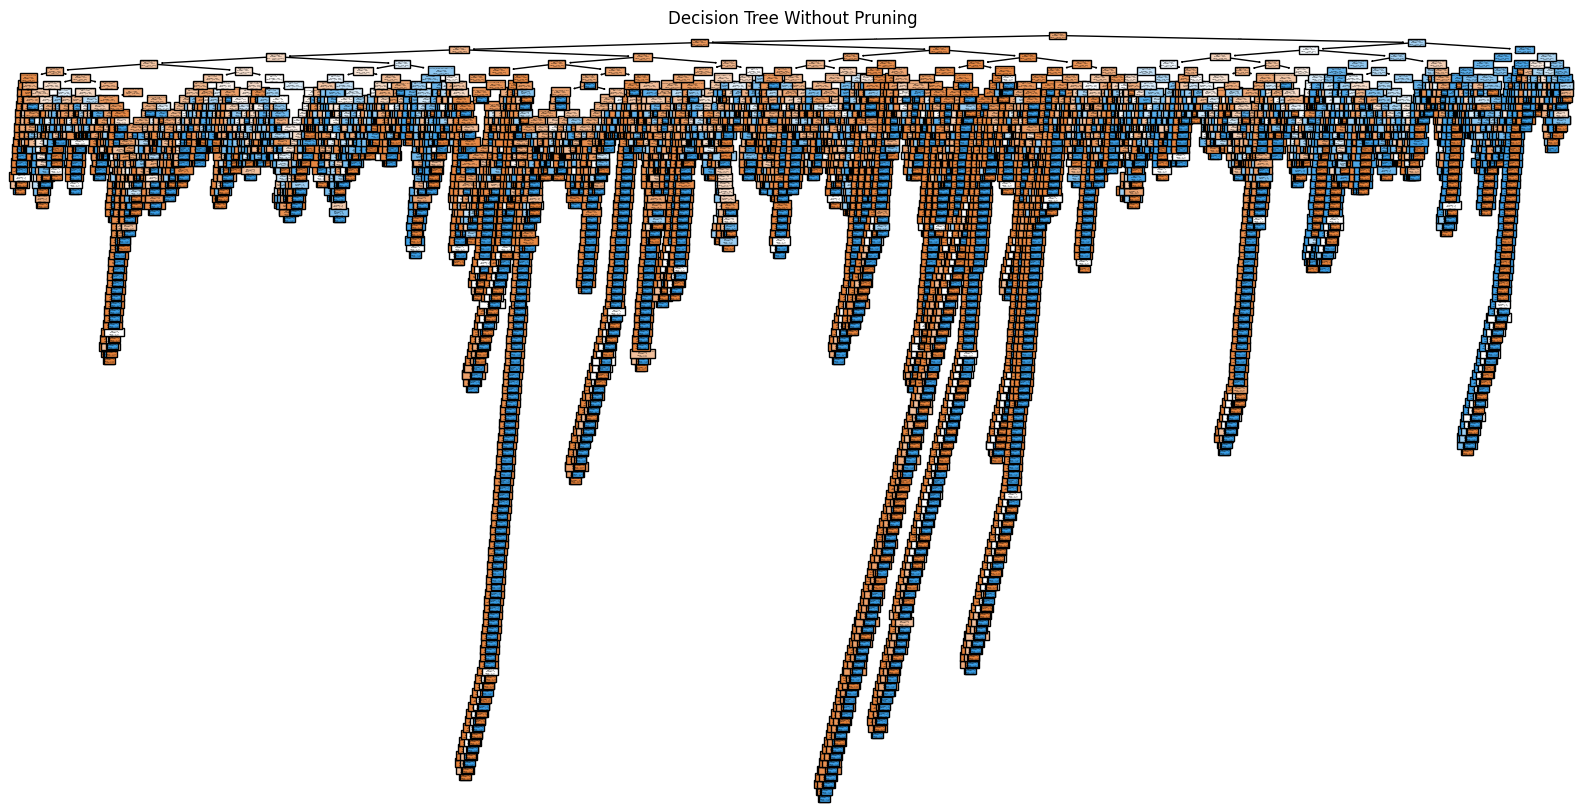

In [ ]:
# Plot unpruned decision tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_unpruned,
    feature_names=X.columns,
    class_names=le.classes_,
    filled=True
)

plt.title("Decision Tree Without Pruning")
plt.show()